In [ ]:
!pip install gymnasium -q

import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import time

print("Gymnasium version:", gym.__version__)

Gymnasium version: 1.4.0


In [ ]:
import gymnasium as gym
import numpy as np

# Try Taxi-v3 first (matches the assignment); fall back to v4 if deprecated
try:
    gym.make("Taxi-v3").close()
    ENV_ID = "Taxi-v3"
except Exception as e:
    print("Taxi-v3 unavailable:", type(e).__name__)
    ENV_ID = "Taxi-v4"

print("Using environment:", ENV_ID)

env = gym.make(ENV_ID)
print("Number of states :", env.observation_space.n)
print("Number of actions:", env.action_space.n)
print("Max steps/episode:", env.spec.max_episode_steps)

state, info = env.reset(seed=42)
print("\nSample initial state:", state)
print("Decoded (taxi_row, taxi_col, passenger_loc, destination):",
      list(env.unwrapped.decode(state)))
print("Info:", info)

# 0=South 1=North 2=East 3=West 4=Pickup 5=Dropoff
print("\nOne sample render:\n")
env_render = gym.make(ENV_ID, render_mode="ansi")
env_render.reset(seed=42)
print(env_render.render())

Taxi-v3 unavailable: DeprecatedEnv
Using environment: Taxi-v4
Number of states : 500
Number of actions: 6
Max steps/episode: 200

Sample initial state: 386
Decoded (taxi_row, taxi_col, passenger_loc, destination): [3, 4, 1, 2]
Info: {'prob': 1.0, 'action_mask': array([1, 1, 0, 1, 0, 0], dtype=int8)}

One sample render:

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




/usr/local/lib/python3.13/dist-packages/gymnasium/envs/registration.py:511: DeprecationWarning: WARN: The environment Taxi-v3 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


In [ ]:
def run_random_baseline(n_episodes=100, seed=0):
    env = gym.make(ENV_ID)
    rewards, steps, successes, penalties = [], [], [], []
    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed + ep)
        done, total_r, n_steps, pen = False, 0, 0, 0
        while not done:
            action = env.action_space.sample()
            state, r, terminated, truncated, _ = env.step(action)
            total_r += r
            n_steps += 1
            if r == -10:
                pen += 1
            done = terminated or truncated
        rewards.append(total_r)
        steps.append(n_steps)
        successes.append(1 if terminated else 0)
        penalties.append(pen)
    return rewards, steps, successes, penalties

r, s, succ, pen = run_random_baseline()

print(f"=== RANDOM BASELINE ({ENV_ID}, 100 episodes) ===")
print(f"Avg reward   : {np.mean(r):.2f}")
print(f"Avg steps    : {np.mean(s):.2f}")
print(f"Success rate : {np.mean(succ)*100:.1f}%")
print(f"Avg penalties: {np.mean(pen):.2f}")

=== RANDOM BASELINE (Taxi-v4, 100 episodes) ===
Avg reward   : -765.48
Avg steps    : 195.60
Success rate : 6.0%
Avg penalties: 63.46


In [ ]:
# ---------- Shared hyperparameters (identical for both agents) ----------
CONFIG = {
    "alpha": 0.1,          # learning rate
    "gamma": 0.99,         # discount factor
    "eps_start": 1.0,
    "eps_min": 0.01,
    "eps_decay": 0.995,    # multiplied per episode
    "episodes": 5000,
}

def epsilon_greedy(Q, state, epsilon, n_actions, rng):
    if rng.random() < epsilon:
        return int(rng.integers(n_actions))
    # break ties randomly so untrained states don't always pick action 0
    q = Q[state]
    return int(rng.choice(np.flatnonzero(q == q.max())))

def train(algo, config=CONFIG, seed=0, env_id=None):
    """algo: 'qlearning' or 'sarsa'. Returns Q-table and per-episode metrics."""
    env = gym.make(env_id or ENV_ID)
    rng = np.random.default_rng(seed)
    nS, nA = env.observation_space.n, env.action_space.n
    Q = np.zeros((nS, nA))

    alpha, gamma = config["alpha"], config["gamma"]
    eps = config["eps_start"]
    m = {k: [] for k in ["reward", "steps", "penalties", "success", "epsilon"]}

    for ep in range(config["episodes"]):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        action = epsilon_greedy(Q, state, eps, nA, rng)
        total_r, n_steps, pen, done = 0, 0, 0, False

        while not done:
            next_state, r, terminated, truncated, _ = env.step(action)
            next_action = epsilon_greedy(Q, next_state, eps, nA, rng)

            if terminated:
                target = r                                   # no bootstrap at terminal
            elif algo == "qlearning":
                target = r + gamma * np.max(Q[next_state])   # off-policy
            elif algo == "sarsa":
                target = r + gamma * Q[next_state, next_action]  # on-policy
            else:
                raise ValueError("algo must be 'qlearning' or 'sarsa'")

            Q[state, action] += alpha * (target - Q[state, action])

            state, action = next_state, next_action
            total_r += r
            n_steps += 1
            pen += (r == -10)
            done = terminated or truncated

        eps = max(config["eps_min"], eps * config["eps_decay"])
        m["reward"].append(total_r)
        m["steps"].append(n_steps)
        m["penalties"].append(pen)
        m["success"].append(int(terminated))
        m["epsilon"].append(eps)

    env.close()
    return Q, {k: np.array(v) for k, v in m.items()}

def evaluate_greedy(Q, n_episodes=100, seed=1000, env_id=None):
    env = gym.make(env_id or ENV_ID)
    rewards, steps, succ, pens = [], [], [], []
    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed + ep)
        done, tot, n, pen = False, 0, 0, 0
        while not done:
            action = int(np.argmax(Q[state]))
            state, r, terminated, truncated, _ = env.step(action)
            tot += r; n += 1; pen += (r == -10)
            done = terminated or truncated
        rewards.append(tot); steps.append(n); succ.append(int(terminated)); pens.append(pen)
    env.close()
    return dict(reward=np.mean(rewards), steps=np.mean(steps),
                success=np.mean(succ) * 100, penalties=np.mean(pens))

In [ ]:
t0 = time.time()
Q_ql, m_ql = train("qlearning", seed=0)
print(f"Q-Learning trained in {time.time()-t0:.1f}s")

t0 = time.time()
Q_sa, m_sa = train("sarsa", seed=0)
print(f"SARSA trained in {time.time()-t0:.1f}s")

def last_n(m, n=100):
    return {k: np.mean(m[k][-n:]) for k in ["reward", "steps", "penalties", "success"]}

print("\nLast 100 training episodes (epsilon is ~0.01 by then):")
print("Q-Learning:", {k: round(float(v), 2) for k, v in last_n(m_ql).items()})
print("SARSA     :", {k: round(float(v), 2) for k, v in last_n(m_sa).items()})

Q-Learning trained in 9.7s
SARSA trained in 7.0s

Last 100 training episodes (epsilon is ~0.01 by then):
Q-Learning: {'reward': 7.68, 'steps': 13.23, 'penalties': 0.01, 'success': 1.0}
SARSA     : {'reward': 6.6, 'steps': 13.77, 'penalties': 0.07, 'success': 1.0}


=== GREEDY EVALUATION (100 test episodes) ===
Q-Learning: {'reward': 7.63, 'steps': 13.37, 'success': 100.0, 'penalties': 0.0}
SARSA     : {'reward': 7.63, 'steps': 13.37, 'success': 100.0, 'penalties': 0.0}

Episodes until 100-ep moving avg reward >= 0:
Q-Learning: 1093
SARSA     : 1161


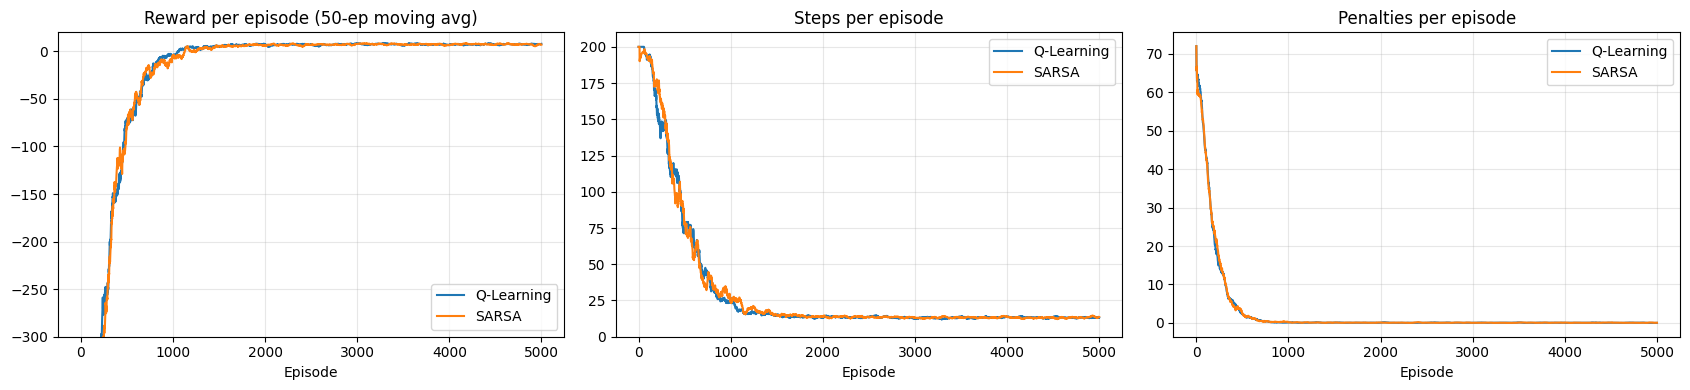

In [ ]:
ev_ql = evaluate_greedy(Q_ql)
ev_sa = evaluate_greedy(Q_sa)

print("=== GREEDY EVALUATION (100 test episodes) ===")
print("Q-Learning:", {k: round(float(v), 2) for k, v in ev_ql.items()})
print("SARSA     :", {k: round(float(v), 2) for k, v in ev_sa.items()})

def smooth(x, w=50):
    return pd.Series(x).rolling(w, min_periods=1).mean().values

def first_episode_reaching(m, threshold=0, w=100):
    ma = pd.Series(m["reward"]).rolling(w).mean().values
    idx = np.where(ma >= threshold)[0]
    return int(idx[0]) + 1 if len(idx) else None

print("\nEpisodes until 100-ep moving avg reward >= 0:")
print("Q-Learning:", first_episode_reaching(m_ql))
print("SARSA     :", first_episode_reaching(m_sa))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for name, m in [("Q-Learning", m_ql), ("SARSA", m_sa)]:
    ax[0].plot(smooth(m["reward"]), label=name)
    ax[1].plot(smooth(m["steps"]), label=name)
    ax[2].plot(smooth(m["penalties"]), label=name)
ax[0].set_title("Reward per episode (50-ep moving avg)"); ax[0].set_ylim(-300, 20)
ax[1].set_title("Steps per episode");                      ax[1].set_ylim(0, 210)
ax[2].set_title("Penalties per episode")
for a in ax:
    a.set_xlabel("Episode"); a.grid(alpha=0.3); a.legend()
plt.tight_layout()
plt.savefig("learning_curves_seed0.png", dpi=150)
plt.show()

In [ ]:
print("Max |Q_ql - Q_sa|      :", np.abs(Q_ql - Q_sa).max().round(3))
print("Mean |Q_ql - Q_sa|     :", np.abs(Q_ql - Q_sa).mean().round(3))
agree = (Q_ql.argmax(1) == Q_sa.argmax(1)).mean() * 100
print(f"States where greedy action agrees: {agree:.1f}%")

Max |Q_ql - Q_sa|      : 17.677
Mean |Q_ql - Q_sa|     : 1.888
States where greedy action agrees: 83.2%


In [ ]:
SEEDS = [0, 1, 2, 3, 4]
results = {"qlearning": [], "sarsa": []}

for algo in ["qlearning", "sarsa"]:
    for sd in SEEDS:
        Q, m = train(algo, seed=sd)
        ev = evaluate_greedy(Q, n_episodes=100, seed=1000)
        results[algo].append(dict(Q=Q, m=m, ev=ev,
                                  conv=first_episode_reaching(m),
                                  final100=last_n(m),
                                  auc=float(np.mean(m["reward"])),     # avg reward over all training
                                  train_pen=int(np.sum(m["penalties"]))))  # total penalties during training
    print(algo, "done")

def summarize(key_fn, name):
    out = {}
    for algo in results:
        vals = np.array([key_fn(r) for r in results[algo]], dtype=float)
        out[algo] = f"{vals.mean():.2f} ± {vals.std():.2f}"
    return name, out["qlearning"], out["sarsa"]

rows = [
    summarize(lambda r: r["ev"]["reward"],            "Greedy eval reward"),
    summarize(lambda r: r["ev"]["steps"],             "Greedy eval steps"),
    summarize(lambda r: r["ev"]["success"],           "Greedy eval success %"),
    summarize(lambda r: r["conv"],                    "Episodes to avg reward >= 0"),
    summarize(lambda r: r["auc"],                     "Avg reward over all training"),
    summarize(lambda r: r["train_pen"],               "Total penalties during training"),
    summarize(lambda r: r["final100"]["reward"],      "Last-100 training reward"),
    summarize(lambda r: r["final100"]["penalties"],   "Last-100 training penalties"),
]
summary_df = pd.DataFrame(rows, columns=["Metric", "Q-Learning (mean±std)", "SARSA (mean±std)"])
print("\n=== 5-SEED SUMMARY ===")
print(summary_df.to_string(index=False))
summary_df.to_csv("summary_5seeds.csv", index=False)
print("\nPer-seed convergence episodes:")
print("Q-Learning:", [r["conv"] for r in results["qlearning"]])
print("SARSA     :", [r["conv"] for r in results["sarsa"]])

qlearning done
sarsa done

=== 5-SEED SUMMARY ===
                         Metric Q-Learning (mean±std) SARSA (mean±std)
             Greedy eval reward           7.63 ± 0.00      7.55 ± 0.14
              Greedy eval steps          13.37 ± 0.00     13.45 ± 0.14
          Greedy eval success %         100.00 ± 0.00    100.00 ± 0.00
    Episodes to avg reward >= 0       1077.60 ± 23.06 1182.20 ± 100.70
   Avg reward over all training         -28.29 ± 0.28    -29.36 ± 0.19
Total penalties during training      10553.20 ± 66.19 10633.80 ± 56.83
       Last-100 training reward           7.25 ± 0.38      7.13 ± 0.43
    Last-100 training penalties           0.03 ± 0.02      0.04 ± 0.02

Per-seed convergence episodes:
Q-Learning: [1093, 1102, 1077, 1081, 1035]
SARSA     : [1161, 1354, 1043, 1202, 1151]


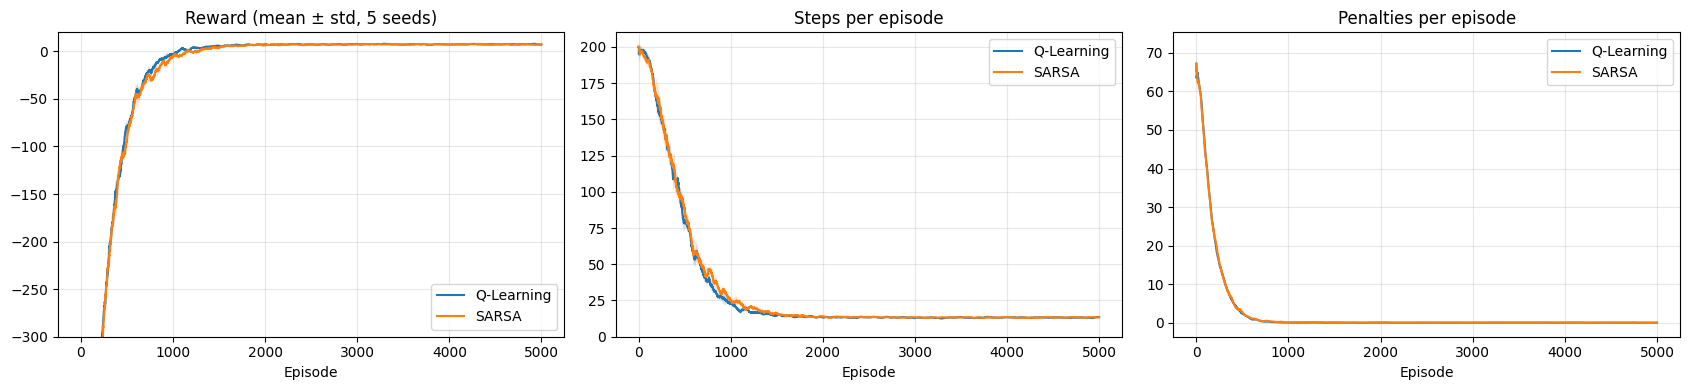

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for algo, label in [("qlearning", "Q-Learning"), ("sarsa", "SARSA")]:
    for i, key in enumerate(["reward", "steps", "penalties"]):
        arr = np.array([smooth(r["m"][key]) for r in results[algo]])
        mu, sd = arr.mean(0), arr.std(0)
        ax[i].plot(mu, label=label)
        ax[i].fill_between(range(len(mu)), mu - sd, mu + sd, alpha=0.2)
ax[0].set_title("Reward (mean ± std, 5 seeds)"); ax[0].set_ylim(-300, 20)
ax[1].set_title("Steps per episode");            ax[1].set_ylim(0, 210)
ax[2].set_title("Penalties per episode")
for a in ax:
    a.set_xlabel("Episode"); a.grid(alpha=0.3); a.legend()
plt.tight_layout()
plt.savefig("learning_curves_5seeds.png", dpi=150)
plt.show()

In [ ]:
from scipy import stats

# (a) per-seed greedy rewards
print("Greedy eval reward per seed")
print("Q-Learning:", [round(r["ev"]["reward"], 2) for r in results["qlearning"]])
print("SARSA     :", [round(r["ev"]["reward"], 2) for r in results["sarsa"]])

# (b) Welch t-tests (small n, so treat p-values as indicative only)
def test(key_fn, name):
    a = [key_fn(r) for r in results["qlearning"]]
    b = [key_fn(r) for r in results["sarsa"]]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    print(f"{name:32s} diff(SARSA-QL) = {np.mean(b)-np.mean(a):9.2f}   Welch p = {p:.4f}")

print("\nSignificance tests (QL vs SARSA, 5 seeds)")
test(lambda r: r["conv"],      "Episodes to avg reward >= 0")
test(lambda r: r["auc"],       "Avg reward over all training")
test(lambda r: r["train_pen"], "Total training penalties")
test(lambda r: r["ev"]["reward"], "Greedy eval reward")

# (c) exact optimal Q via value iteration on the environment's transition model
def value_iteration(env_id, gamma, tol=1e-10):
    env = gym.make(env_id)
    P = env.unwrapped.P
    nS, nA = env.observation_space.n, env.action_space.n
    V = np.zeros(nS)
    while True:
        Q = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                for p, ns, r, term in P[s][a]:
                    Q[s, a] += p * (r + gamma * V[ns] * (not term))
        newV = Q.max(1)
        if np.abs(newV - V).max() < tol:
            return Q
        V = newV

Q_star = value_iteration(ENV_ID, CONFIG["gamma"])

def policy_optimal_pct(Q, Q_star, visited_mask):
    best = np.isclose(Q_star, Q_star.max(1, keepdims=True), atol=1e-6)  # ties allowed
    ok = best[np.arange(len(Q)), Q.argmax(1)]
    return ok[visited_mask].mean() * 100

print("\nGreedy-action optimality vs exact Q* (visited states only, ties counted as optimal)")
for algo, label in [("qlearning", "Q-Learning"), ("sarsa", "SARSA")]:
    pcts, errs = [], []
    for r in results[algo]:
        vm = (r["Q"] != 0).any(1)
        pcts.append(policy_optimal_pct(r["Q"], Q_star, vm))
        errs.append(np.abs(r["Q"][vm] - Q_star[vm]).mean())
    print(f"{label:10s} optimal-action states: {np.mean(pcts):.1f}% (per seed {np.round(pcts,1)}), "
          f"mean |Q-Q*|: {np.mean(errs):.3f}")

Greedy eval reward per seed
Q-Learning: [np.float64(7.63), np.float64(7.63), np.float64(7.63), np.float64(7.63), np.float64(7.63)]
SARSA     : [np.float64(7.63), np.float64(7.27), np.float64(7.59), np.float64(7.63), np.float64(7.61)]

Significance tests (QL vs SARSA, 5 seeds)
Episodes to avg reward >= 0      diff(SARSA-QL) =    104.60   Welch p = 0.1062
Avg reward over all training     diff(SARSA-QL) =     -1.06   Welch p = 0.0004
Total training penalties         diff(SARSA-QL) =     80.60   Welch p = 0.1027
Greedy eval reward               diff(SARSA-QL) =     -0.08   Welch p = 0.2927

Greedy-action optimality vs exact Q* (visited states only, ties counted as optimal)
Q-Learning optimal-action states: 98.1% (per seed [98.5 97.  98.5 98.8 97.8]), mean |Q-Q*|: 8.263
SARSA      optimal-action states: 97.5% (per seed [98.5 96.8 98.  97.2 96.8]), mean |Q-Q*|: 10.067


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


done alpha=0.05
done alpha=0.1
done alpha=0.3
done alpha=0.5
done alpha=0.9
done eps_decay=0.98
done eps_decay=0.99
done eps_decay=0.995
done eps_decay=0.999
    param  value       algo    conv    auc  final100  greedy
    alpha   0.05 Q-Learning 1952.33 -43.86      7.72    2.20
    alpha   0.05      SARSA 2015.33 -43.27      7.53  -13.88
    alpha   0.10 Q-Learning 1090.67 -28.38      7.11    7.63
    alpha   0.10      SARSA 1186.00 -29.41      6.80    7.50
    alpha   0.30 Q-Learning  569.33 -15.49      7.57    7.62
    alpha   0.30      SARSA  665.33 -19.00      6.87    7.31
    alpha   0.50 Q-Learning  508.00 -12.78      7.32    7.58
    alpha   0.50      SARSA  648.00 -18.59      6.17    6.47
    alpha   0.90 Q-Learning  490.00 -10.75      7.41    7.42
    alpha   0.90      SARSA 1018.00 -35.16     -1.43   -7.25
eps_decay   0.98 Q-Learning 1144.00 -17.37      7.47    7.63
eps_decay   0.98      SARSA 1149.00 -17.10      7.21    7.63
eps_decay   0.99 Q-Learning 1095.33 -20.38      7

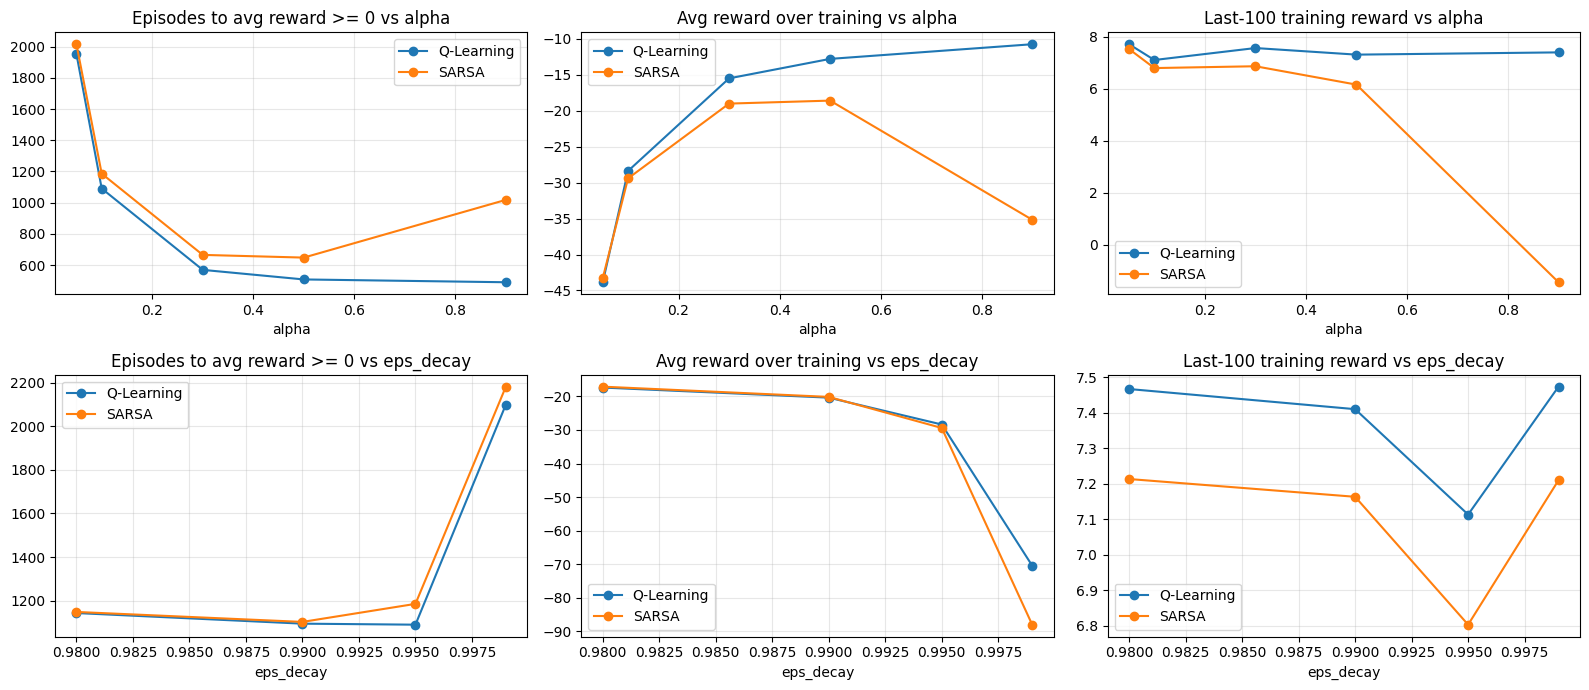

In [ ]:
sweeps = {
    "alpha":     [0.05, 0.1, 0.3, 0.5, 0.9],
    "eps_decay": [0.98, 0.99, 0.995, 0.999],
}
SW_SEEDS = [0, 1, 2]
sens_rows = []

for param, values in sweeps.items():
    for v in values:
        cfg = {**CONFIG, param: v}
        for algo, label in [("qlearning", "Q-Learning"), ("sarsa", "SARSA")]:
            convs, aucs, fins, evs = [], [], [], []
            for sd in SW_SEEDS:
                Q, m = train(algo, config=cfg, seed=sd)
                convs.append(first_episode_reaching(m) or cfg["episodes"])
                aucs.append(np.mean(m["reward"]))
                fins.append(np.mean(m["reward"][-100:]))
                evs.append(evaluate_greedy(Q, 100, 1000)["reward"])
            sens_rows.append(dict(param=param, value=v, algo=label,
                                  conv=np.mean(convs), auc=np.mean(aucs),
                                  final100=np.mean(fins), greedy=np.mean(evs)))
        print(f"done {param}={v}")

sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv("sensitivity.csv", index=False)
print(sens_df.round(2).to_string(index=False))

fig, ax = plt.subplots(2, 3, figsize=(16, 7))
for r_i, param in enumerate(sweeps):
    d = sens_df[sens_df.param == param]
    for c_i, (col, ttl) in enumerate([("conv", "Episodes to avg reward >= 0"),
                                      ("auc", "Avg reward over training"),
                                      ("final100", "Last-100 training reward")]):
        for algo in ["Q-Learning", "SARSA"]:
            dd = d[d.algo == algo]
            ax[r_i, c_i].plot(dd.value, dd[col], marker="o", label=algo)
        ax[r_i, c_i].set_title(f"{ttl} vs {param}")
        ax[r_i, c_i].set_xlabel(param); ax[r_i, c_i].grid(alpha=0.3); ax[r_i, c_i].legend()
plt.tight_layout()
plt.savefig("sensitivity.png", dpi=150)
plt.show()

In [ ]:
# (a) Is the large |Q - Q*| coming from untried actions?
V_star = Q_star.max(1)
print("Error on greedy value |max_a Q - V*| and share of untouched (s,a) entries")
for algo, label in [("qlearning", "Q-Learning"), ("sarsa", "SARSA")]:
    gv, zero = [], []
    for r in results[algo]:
        vm = (r["Q"] != 0).any(1)
        gv.append(np.abs(r["Q"].max(1)[vm] - V_star[vm]).mean())
        zero.append((r["Q"][vm] == 0).mean() * 100)
    print(f"{label:10s} greedy-value error: {np.mean(gv):.3f} (per seed {np.round(gv,3)}), "
          f"entries still exactly 0 in visited states: {np.mean(zero):.1f}%")

# (b) Per-seed check of the alpha=0.9 result
cfg = {**CONFIG, "alpha": 0.9}
print("\nalpha = 0.9, per seed (last-100 training reward | greedy reward | greedy success %)")
for algo, label in [("qlearning", "Q-Learning"), ("sarsa", "SARSA")]:
    for sd in SEEDS:
        Q, m = train(algo, config=cfg, seed=sd)
        ev = evaluate_greedy(Q, 100, 1000)
        print(f"{label:10s} seed {sd}: {np.mean(m['reward'][-100:]):7.2f} | "
              f"{ev['reward']:7.2f} | {ev['success']:5.1f}")

Error on greedy value |max_a Q - V*| and share of untouched (s,a) entries
Q-Learning greedy-value error: 3.580 (per seed [3.576 3.502 3.637 3.602 3.582]), entries still exactly 0 in visited states: 0.1%
SARSA      greedy-value error: 5.245 (per seed [5.228 5.467 5.263 5.144 5.124]), entries still exactly 0 in visited states: 0.0%

alpha = 0.9, per seed (last-100 training reward | greedy reward | greedy success %)
Q-Learning seed 0:    7.58 |    7.51 | 100.0
Q-Learning seed 1:    7.88 |    7.53 | 100.0
Q-Learning seed 2:    6.76 |    7.23 | 100.0
Q-Learning seed 3:    6.98 |    7.49 | 100.0
Q-Learning seed 4:    8.56 |    7.49 | 100.0
SARSA      seed 0:    1.36 |    4.27 |  99.0
SARSA      seed 1:   -1.94 |  -26.71 |  84.0
SARSA      seed 2:   -3.72 |    0.70 |  98.0
SARSA      seed 3:   -3.00 |  -20.59 |  87.0
SARSA      seed 4:   -1.56 |  -31.94 |  90.0


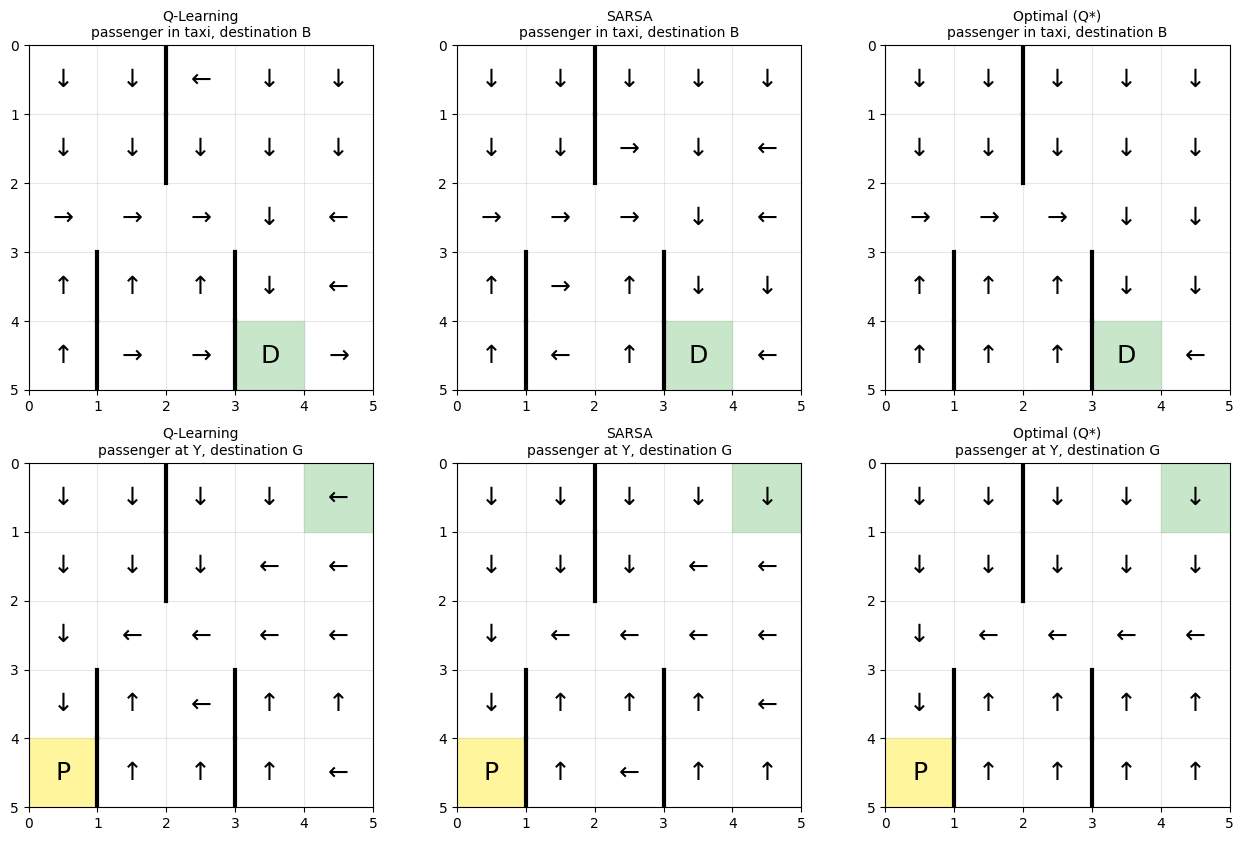

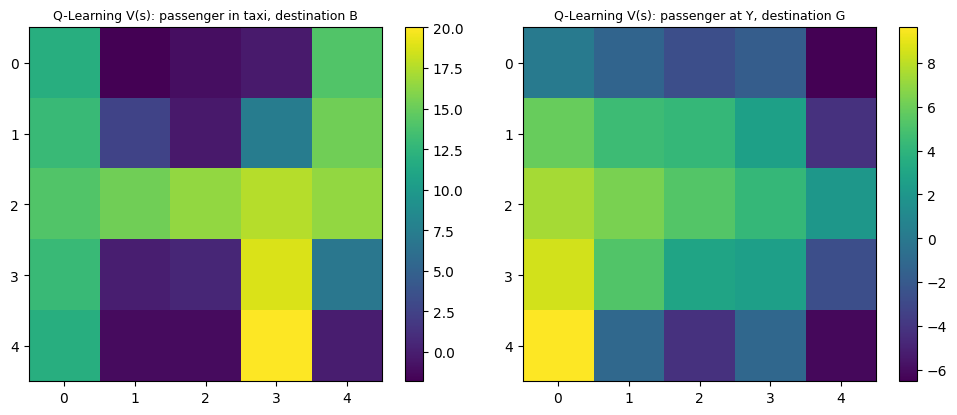

In [ ]:
env_u = gym.make(ENV_ID).unwrapped
arrows = {0: "↓", 1: "↑", 2: "→", 3: "←", 4: "P", 5: "D"}
LOC = {0: (0, 0), 1: (0, 4), 2: (4, 0), 3: (4, 3)}      # R, G, Y, B
LOC_NAME = "RGYB"
# vertical walls: (row, x-boundary)
WALLS = [(0, 2), (1, 2), (3, 1), (4, 1), (3, 3), (4, 3)]

def draw_policy(ax, Q, pass_loc, dest, title):
    for (r_, c_) in [LOC[dest]]:
        ax.add_patch(plt.Rectangle((c_, r_), 1, 1, color="#c8e6c9"))   # destination
    if pass_loc < 4:
        r_, c_ = LOC[pass_loc]
        ax.add_patch(plt.Rectangle((c_, r_), 1, 1, color="#fff59d"))   # passenger waiting
    for row in range(5):
        for col in range(5):
            s = env_u.encode(row, col, pass_loc, dest)
            ax.text(col + 0.5, row + 0.5, arrows[int(np.argmax(Q[s]))],
                    ha="center", va="center", fontsize=18)
    for (row, x) in WALLS:
        ax.plot([x, x], [row, row + 1], color="black", lw=3)
    ax.set_xlim(0, 5); ax.set_ylim(5, 0); ax.set_aspect("equal")
    ax.set_xticks(range(6)); ax.set_yticks(range(6)); ax.grid(alpha=0.3)
    ax.set_title(title, fontsize=10)

configs = [(4, 3, "passenger in taxi, destination B"),
           (2, 1, "passenger at Y, destination G")]
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for i, (pl, dst, desc) in enumerate(configs):
    for j, (Q, nm) in enumerate([(Q_ql, "Q-Learning"), (Q_sa, "SARSA"), (Q_star, "Optimal (Q*)")]):
        draw_policy(axes[i, j], Q, pl, dst, f"{nm}\n{desc}")
plt.tight_layout()
plt.savefig("policy_arrows.png", dpi=150)
plt.show()

# Heatmap of state values V(s) = max_a Q(s,a) for the same two configurations
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (pl, dst, desc) in zip(axes, configs):
    grid = np.array([[Q_ql[env_u.encode(r_, c_, pl, dst)].max() for c_ in range(5)] for r_ in range(5)])
    im = ax.imshow(grid, cmap="viridis"); ax.set_title(f"Q-Learning V(s): {desc}", fontsize=9)
    plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("value_heatmap.png", dpi=150)
plt.show()

In [ ]:
import warnings, shutil
warnings.filterwarnings("ignore")

metrics = {
    "Greedy eval reward":              lambda r: r["ev"]["reward"],
    "Greedy eval steps":               lambda r: r["ev"]["steps"],
    "Greedy eval success %":           lambda r: r["ev"]["success"],
    "Episodes to avg reward >= 0":     lambda r: r["conv"],
    "Avg reward over all training":    lambda r: r["auc"],
    "Total penalties during training": lambda r: r["train_pen"],
    "Last-100 training reward":        lambda r: r["final100"]["reward"],
    "Last-100 training penalties":     lambda r: r["final100"]["penalties"],
}
rows = []
for name, fn in metrics.items():
    a = np.array([fn(r) for r in results["qlearning"]], float)
    b = np.array([fn(r) for r in results["sarsa"]], float)
    p = stats.ttest_ind(a, b, equal_var=False).pvalue if (a.std() + b.std()) > 0 else np.nan
    rows.append([name, f"{a.mean():.2f} ± {a.std(ddof=1):.2f}",
                 f"{b.mean():.2f} ± {b.std(ddof=1):.2f}", "n/a" if np.isnan(p) else f"{p:.4f}"])
final_df = pd.DataFrame(rows, columns=["Metric", "Q-Learning (mean ± sd)", "SARSA (mean ± sd)", "Welch p"])
print(final_df.to_string(index=False))
final_df.to_csv("final_summary_5seeds.csv", index=False)

sens_df["value"] = sens_df["value"].astype(float)
sens_df.round(3).to_csv("sensitivity.csv", index=False)
print("\nSensitivity (3 decimals for eps_decay):")
print(sens_df.round(3).to_string(index=False))

# bundle everything for download
import os
os.makedirs("deliverables", exist_ok=True)
for f in ["learning_curves_seed0.png", "learning_curves_5seeds.png", "sensitivity.png",
          "policy_arrows.png", "value_heatmap.png", "final_summary_5seeds.csv", "sensitivity.csv"]:
    if os.path.exists(f): shutil.copy(f, "deliverables/")
shutil.make_archive("deliverables", "zip", "deliverables")
from google.colab import files
files.download("deliverables.zip")

                         Metric Q-Learning (mean ± sd) SARSA (mean ± sd) Welch p
             Greedy eval reward            7.63 ± 0.00       7.55 ± 0.16  0.2927
              Greedy eval steps           13.37 ± 0.00      13.45 ± 0.16  0.2927
          Greedy eval success %          100.00 ± 0.00     100.00 ± 0.00     n/a
    Episodes to avg reward >= 0        1077.60 ± 25.78  1182.20 ± 112.59  0.1062
   Avg reward over all training          -28.29 ± 0.32     -29.36 ± 0.21  0.0004
Total penalties during training       10553.20 ± 74.01  10633.80 ± 63.54  0.1027
       Last-100 training reward            7.25 ± 0.43       7.13 ± 0.48  0.7025
    Last-100 training penalties            0.03 ± 0.03       0.04 ± 0.02  0.7176

Sensitivity (3 decimals for eps_decay):
    param  value       algo     conv     auc  final100  greedy
    alpha  0.050 Q-Learning 1952.333 -43.857     7.720   2.200
    alpha  0.050      SARSA 2015.333 -43.270     7.533 -13.877
    alpha  0.100 Q-Learning 1090.667 -28.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from scipy.stats import spearmanr

def train_with_visits(algo, config=CONFIG, seed=0):
    env = gym.make(ENV_ID); rng = np.random.default_rng(seed)
    nS, nA = env.observation_space.n, env.action_space.n
    Q = np.zeros((nS, nA)); visits = np.zeros(nS)
    alpha, gamma, eps = config["alpha"], config["gamma"], config["eps_start"]
    for ep in range(config["episodes"]):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        action = epsilon_greedy(Q, state, eps, nA, rng)
        done = False
        while not done:
            visits[state] += 1
            next_state, r, terminated, truncated, _ = env.step(action)
            next_action = epsilon_greedy(Q, next_state, eps, nA, rng)
            if terminated:
                target = r
            elif algo == "qlearning":
                target = r + gamma * np.max(Q[next_state])
            else:
                target = r + gamma * Q[next_state, next_action]
            Q[state, action] += alpha * (target - Q[state, action])
            state, action = next_state, next_action
            done = terminated or truncated
        eps = max(config["eps_min"], eps * config["eps_decay"])
    env.close()
    return Q, visits

for algo, Qref, label in [("qlearning", Q_ql, "Q-Learning"), ("sarsa", Q_sa, "SARSA")]:
    Q, visits = train_with_visits(algo)
    print(f"\n{label}: reproduces earlier Q-table -> {np.allclose(Q, Qref)}")
    vm = visits > 0
    err = np.abs(Q.max(1) - V_star)
    print("Spearman(visits, greedy-value error):", spearmanr(visits[vm], err[vm]))
    bins = pd.qcut(visits[vm], 4, duplicates="drop")
    print(pd.DataFrame({"err": err[vm]}).groupby(bins, observed=True)["err"].agg(["mean", "count"]).round(2))


Q-Learning: reproduces earlier Q-table -> True
Spearman(visits, greedy-value error): SignificanceResult(statistic=np.float64(-0.7922498307541428), pvalue=np.float64(2.0857813311804106e-87))
                 mean  count
(7.999, 257.5]   7.77    100
(257.5, 335.0]   3.79    101
(335.0, 444.5]   2.73     99
(444.5, 1294.0]  0.01    100

SARSA: reproduces earlier Q-table -> True
Spearman(visits, greedy-value error): SignificanceResult(statistic=np.float64(-0.7278296209495947), pvalue=np.float64(3.425707497514986e-67))
                 mean  count
(22.999, 264.0]  9.79    101
(264.0, 327.0]   5.61    101
(327.0, 443.5]   4.62     98
(443.5, 1291.0]  0.83    100


In [ ]:
def train_expected_sarsa(config=CONFIG, seed=0, env_id=None):
    env = gym.make(env_id or ENV_ID)
    rng = np.random.default_rng(seed)
    nS, nA = env.observation_space.n, env.action_space.n
    Q = np.zeros((nS, nA))
    alpha, gamma, eps = config["alpha"], config["gamma"], config["eps_start"]
    m = {k: [] for k in ["reward", "steps", "penalties", "success", "epsilon"]}

    def expected_value(q, eps):
        probs = np.full(nA, eps / nA)
        greedy = np.flatnonzero(q == q.max())          # ties share the greedy mass
        probs[greedy] += (1 - eps) / len(greedy)
        return float(probs @ q)

    for ep in range(config["episodes"]):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        total_r, n_steps, pen, done = 0, 0, 0, False
        while not done:
            action = epsilon_greedy(Q, state, eps, nA, rng)
            next_state, r, terminated, truncated, _ = env.step(action)
            target = r if terminated else r + gamma * expected_value(Q[next_state], eps)
            Q[state, action] += alpha * (target - Q[state, action])
            state = next_state
            total_r += r; n_steps += 1; pen += (r == -10)
            done = terminated or truncated
        eps = max(config["eps_min"], eps * config["eps_decay"])
        m["reward"].append(total_r); m["steps"].append(n_steps)
        m["penalties"].append(pen); m["success"].append(int(terminated))
        m["epsilon"].append(eps)
    env.close()
    return Q, {k: np.array(v) for k, v in m.items()}

# ---- 5 seeds, same metrics as before ----
results["expsarsa"] = []
t0 = time.time()
for sd in SEEDS:
    Q, m = train_expected_sarsa(seed=sd)
    ev = evaluate_greedy(Q, 100, 1000)
    results["expsarsa"].append(dict(Q=Q, m=m, ev=ev, conv=first_episode_reaching(m),
                                    final100=last_n(m), auc=float(np.mean(m["reward"])),
                                    train_pen=int(np.sum(m["penalties"]))))
print(f"Expected SARSA done in {time.time()-t0:.0f}s")

names = {"qlearning": "Q-Learning", "sarsa": "SARSA", "expsarsa": "Expected SARSA"}
rows = []
for name, fn in metrics.items():          # `metrics` dict from Cell 14
    row = [name]
    vals = {a: np.array([fn(r) for r in results[a]], float) for a in names}
    for a in names:
        row.append(f"{vals[a].mean():.2f} ± {vals[a].std(ddof=1):.2f}")
    for other in ["qlearning", "sarsa"]:
        v = vals["expsarsa"], vals[other]
        p = stats.ttest_ind(*v, equal_var=False).pvalue if (v[0].std() + v[1].std()) > 0 else np.nan
        row.append("n/a" if np.isnan(p) else f"{p:.4f}")
    rows.append(row)
three_df = pd.DataFrame(rows, columns=["Metric", "Q-Learning", "SARSA", "Expected SARSA",
                                       "p (ExpSARSA vs QL)", "p (ExpSARSA vs SARSA)"])
print(three_df.to_string(index=False))
three_df.to_csv("final_summary_3algos.csv", index=False)
print("\nPer-seed convergence episodes:",
      {names[a]: [r["conv"] for r in results[a]] for a in names})

Expected SARSA done in 50s
                         Metric       Q-Learning            SARSA   Expected SARSA p (ExpSARSA vs QL) p (ExpSARSA vs SARSA)
             Greedy eval reward      7.63 ± 0.00      7.55 ± 0.16      7.63 ± 0.00                n/a                0.2927
              Greedy eval steps     13.37 ± 0.00     13.45 ± 0.16     13.37 ± 0.00                n/a                0.2927
          Greedy eval success %    100.00 ± 0.00    100.00 ± 0.00    100.00 ± 0.00                n/a                   n/a
    Episodes to avg reward >= 0  1077.60 ± 25.78 1182.20 ± 112.59  1141.00 ± 61.68             0.0837                0.4991
   Avg reward over all training    -28.29 ± 0.32    -29.36 ± 0.21    -27.15 ± 0.32             0.0005                0.0000
Total penalties during training 10553.20 ± 74.01 10633.80 ± 63.54 10210.40 ± 49.97             0.0001                0.0000
       Last-100 training reward      7.25 ± 0.43      7.13 ± 0.48      7.37 ± 0.33             0.6284    

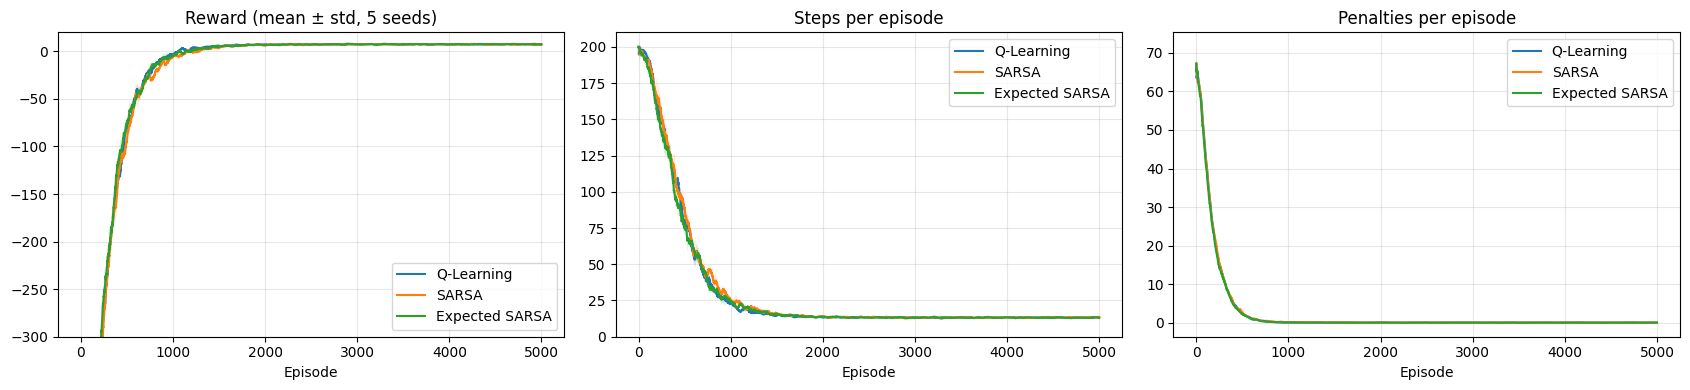

done alpha = 0.05
done alpha = 0.1
done alpha = 0.3
done alpha = 0.5
done alpha = 0.9
param  value           algo    conv    auc  final100  greedy
alpha   0.05 Expected SARSA 2055.00 -42.57      7.21  -11.84
alpha   0.05     Q-Learning 1952.33 -43.86      7.72    2.20
alpha   0.05          SARSA 2015.33 -43.27      7.53  -13.88
alpha   0.10 Expected SARSA 1143.33 -27.07      7.34    7.63
alpha   0.10     Q-Learning 1090.67 -28.38      7.11    7.63
alpha   0.10          SARSA 1186.00 -29.41      6.80    7.50
alpha   0.30 Expected SARSA  644.33 -15.72      7.23    7.62
alpha   0.30     Q-Learning  569.33 -15.49      7.57    7.62
alpha   0.30          SARSA  665.33 -19.00      6.87    7.31
alpha   0.50 Expected SARSA  532.33 -12.39      7.43    7.61
alpha   0.50     Q-Learning  508.00 -12.78      7.32    7.58
alpha   0.50          SARSA  648.00 -18.59      6.17    6.47
alpha   0.90 Expected SARSA  507.00  -9.90      7.46    7.54
alpha   0.90     Q-Learning  490.00 -10.75      7.41    7.42

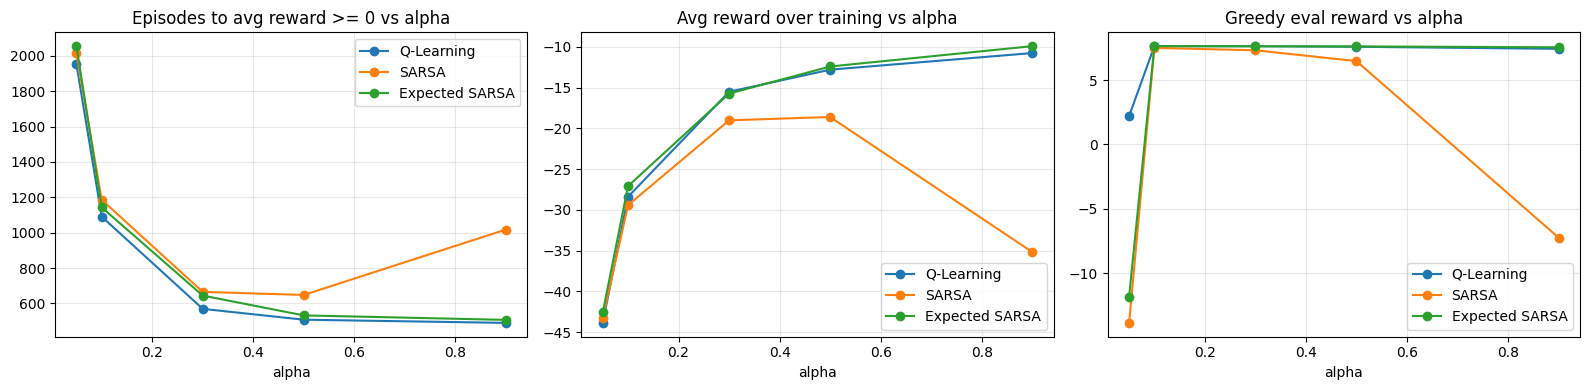


Expected SARSA, alpha = 0.9, per seed (last-100 reward | greedy reward | greedy success %)
seed 0:    7.36 |    7.55 | 100.0
seed 1:    7.54 |    7.61 | 100.0
seed 2:    7.48 |    7.47 | 100.0
seed 3:    7.57 |    7.63 | 100.0
seed 4:    7.62 |    7.57 | 100.0


In [ ]:
# (a) mean learning curves, 5 seeds
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for algo, label in names.items():
    for i, key in enumerate(["reward", "steps", "penalties"]):
        arr = np.array([smooth(r["m"][key]) for r in results[algo]])
        mu, sd = arr.mean(0), arr.std(0)
        ax[i].plot(mu, label=label)
        ax[i].fill_between(range(len(mu)), mu - sd, mu + sd, alpha=0.15)
ax[0].set_title("Reward (mean ± std, 5 seeds)"); ax[0].set_ylim(-300, 20)
ax[1].set_title("Steps per episode");            ax[1].set_ylim(0, 210)
ax[2].set_title("Penalties per episode")
for a in ax:
    a.set_xlabel("Episode"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig("learning_curves_3algos.png", dpi=150); plt.show()

# (b) alpha sweep for Expected SARSA (3 seeds, same protocol as Cell 11)
es_rows = []
for v in [0.05, 0.1, 0.3, 0.5, 0.9]:
    cfg = {**CONFIG, "alpha": v}
    convs, aucs, fins, evs = [], [], [], []
    for sd in SW_SEEDS:
        Q, m = train_expected_sarsa(config=cfg, seed=sd)
        convs.append(first_episode_reaching(m) or cfg["episodes"])
        aucs.append(np.mean(m["reward"])); fins.append(np.mean(m["reward"][-100:]))
        evs.append(evaluate_greedy(Q, 100, 1000)["reward"])
    es_rows.append(dict(param="alpha", value=v, algo="Expected SARSA", conv=np.mean(convs),
                        auc=np.mean(aucs), final100=np.mean(fins), greedy=np.mean(evs)))
    print("done alpha =", v)
es_df = pd.DataFrame(es_rows)
sens_all = pd.concat([sens_df[sens_df.param == "alpha"], es_df], ignore_index=True)
sens_all.round(3).to_csv("sensitivity_alpha_3algos.csv", index=False)
print(sens_all.sort_values(["value", "algo"]).round(2).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for c_i, (col, ttl) in enumerate([("conv", "Episodes to avg reward >= 0"),
                                  ("auc", "Avg reward over training"),
                                  ("greedy", "Greedy eval reward")]):
    for algo in ["Q-Learning", "SARSA", "Expected SARSA"]:
        d = sens_all[sens_all.algo == algo]
        ax[c_i].plot(d.value, d[col], marker="o", label=algo)
    ax[c_i].set_title(f"{ttl} vs alpha"); ax[c_i].set_xlabel("alpha")
    ax[c_i].grid(alpha=0.3); ax[c_i].legend()
plt.tight_layout(); plt.savefig("sensitivity_alpha_3algos.png", dpi=150); plt.show()

# (c) per-seed check at alpha = 0.9 (5 seeds)
cfg = {**CONFIG, "alpha": 0.9}
print("\nExpected SARSA, alpha = 0.9, per seed (last-100 reward | greedy reward | greedy success %)")
for sd in SEEDS:
    Q, m = train_expected_sarsa(config=cfg, seed=sd)
    ev = evaluate_greedy(Q, 100, 1000)
    print(f"seed {sd}: {np.mean(m['reward'][-100:]):7.2f} | {ev['reward']:7.2f} | {ev['success']:5.1f}")

In [ ]:
import os, shutil
from google.colab import files
for f in ["learning_curves_3algos.png", "sensitivity_alpha_3algos.png",
          "final_summary_3algos.csv", "sensitivity_alpha_3algos.csv"]:
    if os.path.exists(f): shutil.copy(f, "deliverables/")
shutil.make_archive("deliverables", "zip", "deliverables")
files.download("deliverables.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# Sample state-by-state predictions
env = gym.make(ENV_ID)
env_u = env.unwrapped

action_names = {
    0: "South",
    1: "North",
    2: "East",
    3: "West",
    4: "Pickup",
    5: "Dropoff"
}

samples = [
    (0, 0, 0, 1),
    (2, 3, 2, 1),
    (4, 4, 4, 3),
    (1, 2, 4, 0),
    (3, 0, 1, 2)
]

rows = []

for taxi_row, taxi_col, passenger_loc, destination in samples:
    state = env_u.encode(
        taxi_row, taxi_col, passenger_loc, destination
    )

    ql_action = int(np.argmax(Q_ql[state]))
    sarsa_action = int(np.argmax(Q_sa[state]))
    optimal_action = int(np.argmax(Q_star[state]))

    rows.append({
        "State": state,
        "Taxi position": (taxi_row, taxi_col),
        "Passenger location/status": passenger_loc,
        "Destination": destination,
        "Q-Learning action": action_names[ql_action],
        "SARSA action": action_names[sarsa_action],
        "Optimal action": action_names[optimal_action]
    })

predictions_df = pd.DataFrame(rows)
display(predictions_df)

predictions_df.to_csv(
    "sample_predictions.csv", index=False
)

env.close()

,State,Taxi position,Passenger location/status,Destination,Q-Learning action,SARSA action,Optimal action
0,1,"(0, 0)",0,1,Pickup,Pickup,Pickup
1,269,"(2, 3)",2,1,West,West,West
2,499,"(4, 4)",4,3,East,West,West
3,156,"(1, 2)",4,0,South,South,South
4,306,"(3, 0)",1,2,North,North,North
